## Color Thresholding in OpenCV

This notebook demonstrates **color thresholding** using OpenCV. The main idea is to select a specific color range by defining **lower** and **upper** bounds, create a **binary mask**, and then use that mask to isolate or replace the selected region.

In the lecture, HSV is recommended for thresholding because it separates **color** from **brightness**, making color targeting more reliable than RGB.

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# !pip install matplotlib
# !pip install numpy

### Load the Image and Prepare Two Color Spaces

OpenCV reads images in **BGR** by default. In this notebook, we create:

- an RGB version for correct visualization with Matplotlib,
- an HSV version for thresholding.

This follows the lecture idea that we usually **display** images in RGB but **process** color ranges in HSV.

In [3]:
image = cv.imread("../../data/raw/images/giraffe-Kenya.png")
image.shape

(1600, 1067, 3)

In [4]:
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)
image_hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)

### Visualize the Original Image

Before thresholding, we first inspect the image in a human-friendly format. This helps us understand which region or color range we want to target.

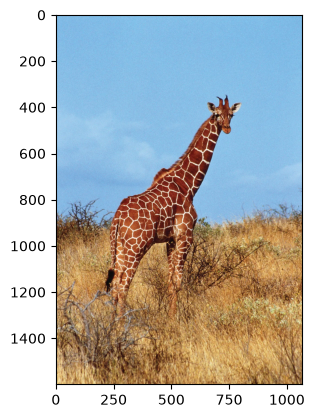

In [5]:
plt.imshow(image_rgb)

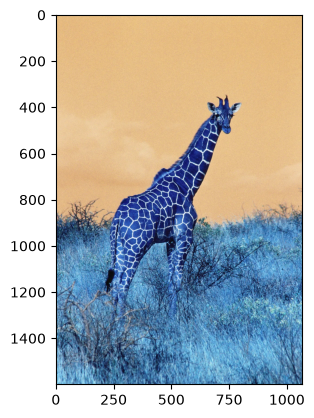

In [6]:
## Show th BGR image
plt.imshow(image)

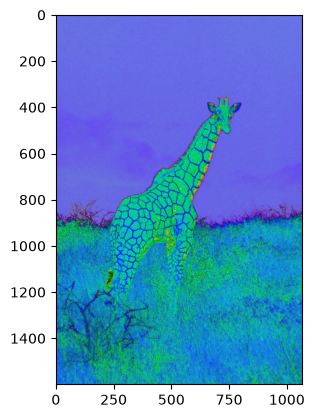

In [7]:
## Show the hsv image
plt.imshow(image_hsv);

### Define the HSV Threshold Range

Color thresholding works by selecting all pixels whose HSV values fall inside a chosen interval.

- `lower_white` is the lower bound.
- `upper_white` is the upper bound.

Any pixel inside this range will be selected by the mask. In OpenCV, HSV uses the scaled range:

- Hue: `0` to `179`
- Saturation: `0` to `255`
- Value: `0` to `255`

So these bounds are written using **OpenCV HSV values**, not textbook HSV degrees and percentages.

In [8]:
lower_white = np.array([0,0,190])
upper_white = np.array([30,80,255])

### Create a Binary Mask with `cv2.inRange()`

`cv2.inRange()` compares every pixel against the threshold bounds.

- If the pixel lies inside the range, the mask gets a high value.
- Otherwise, the mask gets `0`.

The result is a **one-channel binary mask**, which is exactly what the lecture described: white means selected, black means rejected.

In [9]:
mask = cv.inRange(image_hsv, lower_white, upper_white)

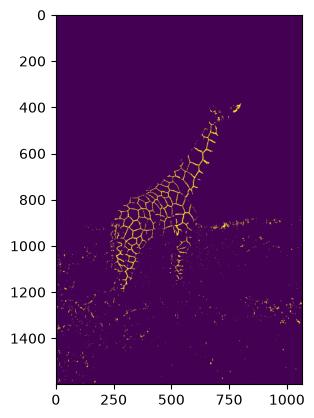

In [10]:
plt.imshow(mask)

### Prepare the Replacement Color

After creating the mask, we need a replacement color for the selected region.

Here, the color is first defined in HSV and then converted to BGR. That is useful because the working output image is a copy of the original OpenCV image, which is still in **BGR** format.

In [11]:
black_hsv = np.uint8([[[120, 255, 0]]])
black_bgr = cv.cvtColor(black_hsv, cv.COLOR_HSV2BGR)[0][0]

### Replace the Selected Pixels Using the Mask

This is the core color-thresholding step:

- keep the original pixel when the mask is `0`,
- replace the pixel when the mask is greater than `0`.

This matches the lecture logic: *if mask is present, replace the target region; otherwise, keep the original image*.

In [12]:
image_result = image.copy()
image_result[mask>0] = black_bgr

### Convert the Result for Visualization

Because Matplotlib expects RGB-like display ordering, the final result is converted from BGR to RGB before plotting. This keeps the displayed colors correct.

In [13]:
image_result_rgb = cv.cvtColor(image_result, cv.COLOR_BGR2RGB)

### Final Comparison

The final plot compares three important stages:

- the original image,
- the binary mask,
- the thresholded and modified result.

This gives a complete view of the pipeline: **image -> HSV threshold -> mask -> selective replacement**.

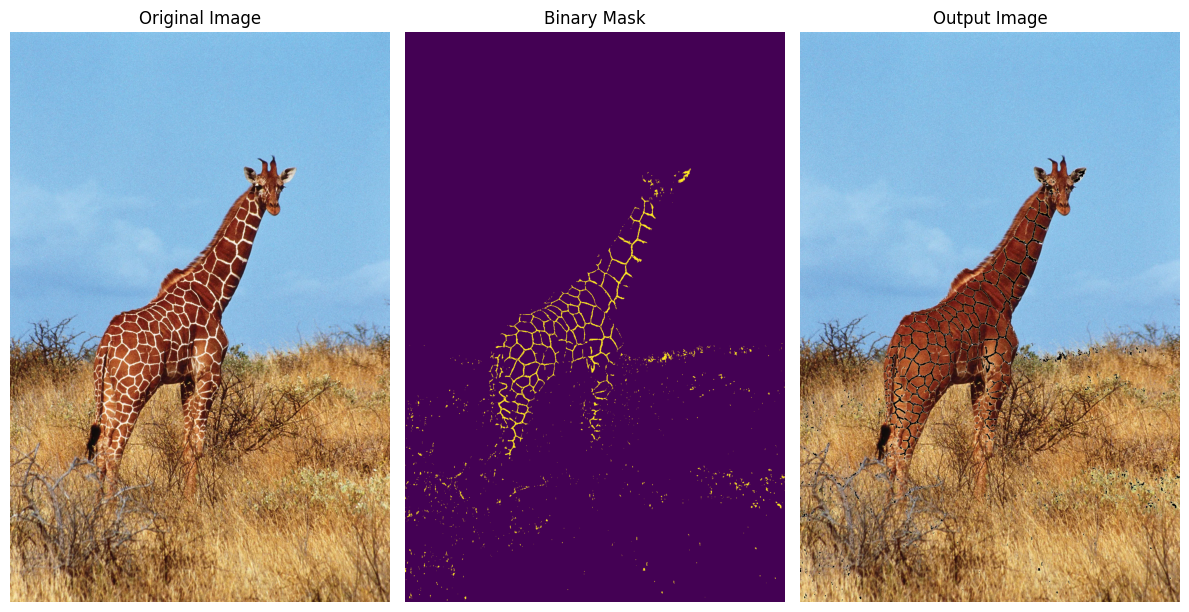

In [17]:
# PLOT

fig, axs = plt.subplots(1,3, figsize=(12,6))

axs[0].imshow(image_rgb)
axs[0].set_title("Original Image")
axs[0].axis('off')

axs[1].imshow(mask)
axs[1].set_title("Binary Mask")
axs[1].axis('off')


axs[2].imshow(image_result_rgb)
axs[2].set_title("Output Image")
axs[2].axis('off')

plt.tight_layout()
plt.show()

## remove-background

In [2]:
## load the image
img_path = "../../data/raw/images/peoples-brown.png"
human_img = cv.imread(img_path)
human_img.shape

(572, 1024, 3)

In [3]:
## convert to rgb and hsv
rgb_peoples = cv.cvtColor(human_img, cv.COLOR_BGR2RGB)
hsv_peoples = cv.cvtColor(human_img, cv.COLOR_BGR2HSV)

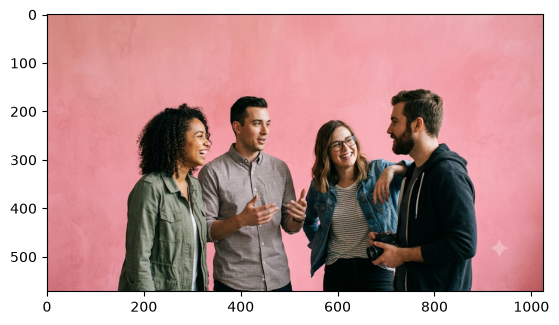

In [4]:
plt.imshow(rgb_peoples)

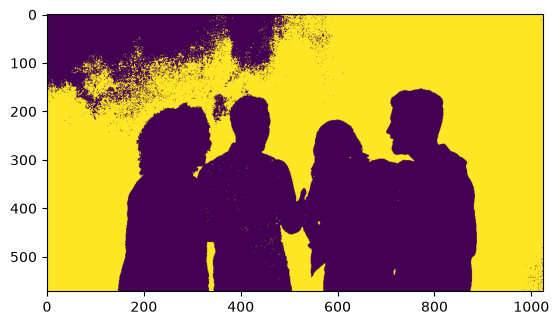

In [5]:
## Create mask to replace background
# Mask 1: Captures the magenta/pink tones (high hue values)
lower_limit = np.array([(140, 30, 50)])
upper_limit = np.array([(179, 255, 255)])

mask1 = cv.inRange(hsv_peoples, lower_limit, upper_limit)
plt.imshow(mask1)

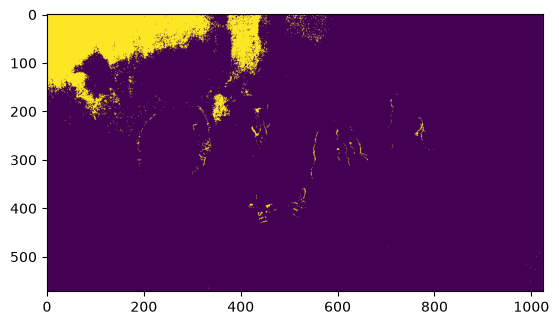

In [6]:
# Mask 2: Captures the warm red/orange tones in the top left corner (low hue values)
lower_limit2 = np.array([0, 85, 200])
upper_limit2 = np.array([10, 255, 255])
mask2 = cv.inRange(hsv_peoples, lower_limit2, upper_limit2)
plt.imshow(mask2)

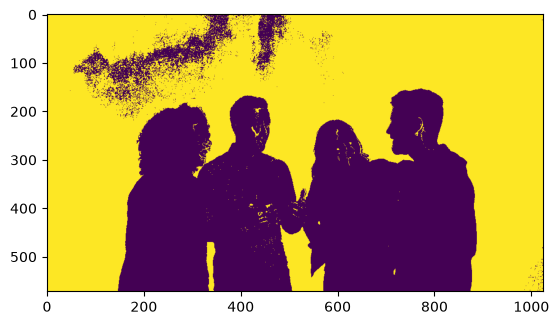

In [7]:
## Combine both masks
final_mask = cv.bitwise_or(mask1, mask2)
plt.imshow(final_mask)

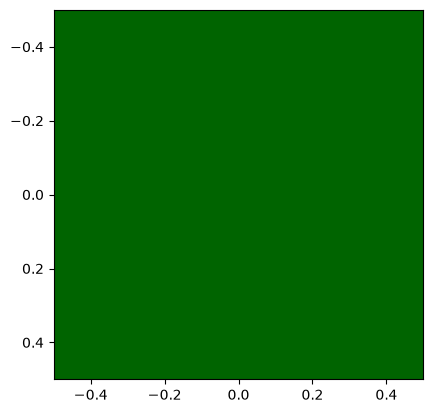

In [12]:
green_hsv = np.uint8([[[60, 255, 100]]])
green_bgr = cv.cvtColor(green_hsv, cv.COLOR_HSV2BGR)

plt.imshow(green_bgr)

In [14]:
green_bgr[0][0]

array([  0, 100,   0], dtype=uint8)

In [22]:
mask1

array([[  0,   0,   0, ..., 255, 255, 255],
       [  0,   0,   0, ..., 255, 255, 255],
       [  0,   0,   0, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]],
      shape=(572, 1024), dtype=uint8)

In [24]:
final_mask

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]],
      shape=(572, 1024), dtype=uint8)

In [31]:
human_img_result = human_img.copy()
human_img_result[final_mask>0]=green_bgr[0][0]
human_img_result

array([[[  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0],
        ...,
        [  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0]],

       [[  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0],
        ...,
        [  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0]],

       [[  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0],
        ...,
        [  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0]],

       ...,

       [[  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0],
        ...,
        [  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0]],

       [[  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0],
        ...,
        [  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0]],

       [[  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0],
        ...,
        [  0, 100,   0],
        [  0, 100,   0],
        [  0, 100,   0]]

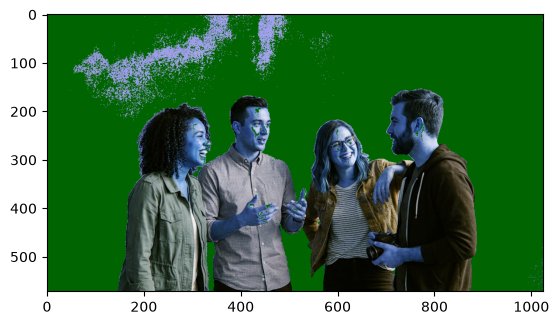

In [32]:
plt.imshow(human_img_result)